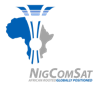 &nbsp;&nbsp; 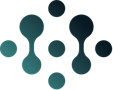

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Publica-AI/nigcomsat-ai-developer/blob/jasons-restructure/Jasons-Restructure/week-1/day-3-rolling-windows/2-exercise/W1D3-exercise.ipynb)

# 🌊 Week 1 · Day 3: Calm Down the Noise: Rolling Windows

**Today:** daily NOC tickets zig-zag every week. You'll smooth them with a **rolling window**, then find out exactly what smoothing **hides**.

| Symbol | Means |
|---|---|
| 📖 | Read this |
| ▶️ | Run the cell below (click it, then press **Shift + Enter**) |
| ✍️ | Your turn: replace every `___` with your answer |
| ✅ / ❌ | The check tells you if you got it right, with a hint if not |
| 🌶️ | Bonus task for fast finishers |

> ## ⚠️ Do this FIRST: **File → Save a copy in Drive**
> Work in your copy (the new tab), not the original.

**Rule book:** keep `W1D3-rulebook.pdf` open next to you.

## ▶️ STEP 0: Set up (run this once, every time you open the notebook)

Click the cell below and press **Shift + Enter**. Wait for `✅ Ready!`. If Colab says *"This notebook was not authored by Google"*, click **Run anyway**.

In [ ]:
#@title 🚀 STEP 0 · Run me first (click the ▶ button on the left of this cell) { display-mode: "form" }
import sys, warnings
warnings.filterwarnings("ignore")
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from pathlib import Path
from urllib.request import urlretrieve

pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (11, 3.6), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "axes.titleweight": "bold",
                     "axes.prop_cycle": plt.cycler(color=["#0A5DB4", "#C77700", "#008C7E"])})

IN_COLAB = "google.colab" in sys.modules
RAW = "https://raw.githubusercontent.com/Publica-AI/nigcomsat-ai-developer/main/Time-series"
DATA_HOME = {'additive_multiplicative_demo': 'week-03', 'bandwidth_throughput_daily': 'week-03', 'ka_band_availability_daily': 'week-03', 'ka_band_availability_monthly': 'week-03', 'link_margin_hourly_aug2025': 'week-03', 'noc_tickets_daily': 'week-03', 'noc_tickets_weekly': 'week-03', 'transponder_utilisation_monthly': 'week-03', 'vsat_uptime_by_region_weekly': 'week-03', 'rf_link_quality_hourly': 'week-03', 'bus_power_telemetry_hourly': 'week-04', 'battery_health_daily': 'week-04', 'twta_thermal_daily': 'week-04', 'telemetry_anomaly_labels': 'week-04', 'bus_telemetry_multivariate_hourly': 'week-05', 'anomaly_labels_week5': 'week-05', 'degradation_assets_daily': 'week-06', 'degradation_thresholds': 'week-06', 'ops_tickets_weekly': 'week-06'}

def data_path(name, week=None):
    """Download a course CSV once and return where it is saved.
    week: which original folder to use, e.g. "week-03" (two files exist in both week-03 and week-04).
    If you uploaded the file yourself (Files panel), that copy is used instead."""
    uploaded = Path(f"{name}.csv")
    if uploaded.exists():
        return uploaded
    week = week or DATA_HOME[name]
    local = Path("course_data") / week / f"{name}.csv"
    if not local.exists():
        local.parent.mkdir(parents=True, exist_ok=True)
        urlretrieve(f"{RAW}/{week}/data/{name}.csv", local)
    return local

def load_labels(name="telemetry_anomaly_labels", week=None):
    """Read an answer-key (labels) file. The original telemetry_anomaly_labels.csv has a stray comma
    inside one description, which makes pd.read_csv crash, so the last column is read as free text."""
    lines = Path(data_path(name, week)).read_text(encoding="utf-8").splitlines()
    cols = lines[0].split(",")
    rows = [ln.split(",", len(cols) - 1) for ln in lines[1:] if ln.strip()]
    df = pd.DataFrame(rows, columns=cols)
    for c in ("start", "end"):
        if c in df:
            df[c] = pd.to_datetime(df[c], format="mixed")
    return df

___ = None          # this is "the blank". Replace every ___ with your answer.
SCORE = {}

def _blank(x):
    return x is None or (isinstance(x, tuple) and any(v is None for v in x))

def check(task, answer):
    """Marks one task. Prints ✅ or ❌ with a hint."""
    if _blank(answer):
        print("✍️  Fill in the blank first: replace ___ with your answer, then run the cell again.")
        return
    try:
        ok, good, hint = CHECKS[task](answer)
    except Exception as e:
        ok, good, hint = False, "", f"{HINTS.get(task, 'Read the task again.')}  (Python said: {type(e).__name__})"
    SCORE[task] = ok
    print(("✅ " + good) if ok else ("❌ Not yet. Hint: " + hint))

def scoreboard():
    got = sum(SCORE.values())
    print(f"You have {got} of {len(CHECKS)} tasks correct.")
    print("🏆 Oya, you don finish! Mad o!" if got == len(CHECKS) else "💪 Keep going: scroll up and fix the ❌ ones.")

# ---- today's checks ----
def _tk():
    return pd.read_csv(data_path("noc_tickets_daily"), parse_dates=["date"], index_col="date").asfreq("D")

def _c_a1(x):
    return x == "date", "Yes! The time column is called \"date\". Same recipe as Day 1, different file.", \
        "Look at the CSV's first column name. Remember the quotes."

def _c_a2(x):
    t = str(x).strip().lower()
    ok = t in {"half", "a half", "1/2", "0.5"} or (isinstance(x, (int, float)) and abs(x - 0.5) < 0.06)
    return ok, "Half! Weekends run at about half of weekdays. Even faults rest on Sunday. 😴", \
        "Compare the weekday and weekend averages printed above. Is it a quarter, half or the same?"

def _c_b1(x):
    return int(x) == 7, "7! One full week in every window, so every weekday appears exactly once.", \
        "How many days are in one week?"

def _c_b2(x):
    return int(x) == 6, "6 NaN rows: a 7-day average genuinely does not exist until day 7. Nothing is broken. 👍", \
        "Count the NaN values at the top of roll7, or use tk[\"roll7\"].isna().sum()."

def _c_b3(x):
    return int(x) == 3, "The 3-day line still zig-zags: sometimes the weekend is inside the window, sometimes not.", \
        "Which line still jumps up and down every week? 3, 7 or 30?"

def _c_b4(x):
    s = _tk()["tickets_raised"]
    b = s.rolling(7).mean().groupby(s.index.day_name()).mean()
    real = b.max() - b.min()
    return abs(float(x) - real) < 0.01, f"Spread of only {real:.2f} tickets: the weekend effect has cancelled out. That's why 7 is the natural first choice.", \
        "Copy the 3-day line above: roll7_by_day.max() - roll7_by_day.min()"

def _c_b5(x):
    return x is True, "center=True puts the window in the middle: 15 days back AND 15 days into the future. 🔮", \
        "To centre the window, set CENTER to True (no quotes, capital T)."

def _c_b6(x):
    return str(x).strip().lower() in {"no", "false"}, \
        "Correct: the centred line is empty (NaN) on the last days, because the future hasn't happened yet. Reports only, never live monitoring.", \
        "Look at the last 3 values of the centred line printed above. Are they numbers?"

def _c_b7(x):
    real = len(_tk()["tickets_raised"].resample("W").sum())
    return int(x) == real, f"{real} weekly buckets (one value per week), versus 730 rolling values (one per day). Different question, different answer.", \
        "Use len(weekly)."

def _c_b8(x):
    return str(x).strip().lower() == "high", "High alpha follows the data closely and reacts fast. Low alpha is smooth and slow. 🐢", \
        "Which line hugs the grey daily line: alpha 0.5 or alpha 0.05? 0.5 is the HIGH one."

def _c_b9(x):
    real = (_tk()["priority_1"] == 0).mean()
    return abs(float(x) - real) < 0.005, f"{real:.1%} of days had zero priority-1 tickets. Small counts jump around, so they need wider windows.", \
        "Try (tk[\"priority_1\"] == 0).mean(): the share of True values."

def _c_b10(x):
    rf = pd.read_csv(data_path("rf_link_quality_hourly"), parse_dates=["timestamp"], index_col="timestamp").asfreq("h")
    m = rf["link_margin_db"]
    want = (int((m < 0).sum()), int((m.rolling(24).mean() < 0).sum()))
    got = (int(x[0]), int(x[1]))
    return got == want, f"{want[0]} real outage hours, {want[1]} on the smoothed line. The average swallowed every outage. SLAs come from raw data! 🚫", \
        "Count with (margin < 0).sum() for the raw line and (smooth < 0).sum() for the 24-hour average."

def _c_b11(x):
    q = pd.read_csv(data_path("noc_tickets_weekly"), parse_dates=["week_start"], index_col="week_start")["tickets_raised"]
    ok = abs(float(x[0]) - q.mean()) < 0.05 and str(x[1]).strip().lower() in {"no", "false"}
    return ok, f"Mean {q.mean():.1f} tickets a week, and 38 → 41 is just noise. Don't call a meeting. ☕", \
        "First answer: weekly[\"tickets_raised\"].mean(). Second: \"yes\" or \"no\": is a 3-ticket change bigger than the usual wobble?"

def _c_bonus(x):
    q = pd.read_csv(data_path("noc_tickets_weekly"), parse_dates=["week_start"], index_col="week_start")["tickets_raised"]
    real = int(((q - q.mean()).abs() > 2 * q.std()).sum())
    return int(x) == real, f"Only {real} odd week in the whole year, in the rainy season. That's the one worth a question. 🌶️", \
        "Count weeks where (value - mean).abs() > 2 * std."

CHECKS = {"A1": _c_a1, "A2": _c_a2, "B1": _c_b1, "B2": _c_b2, "B3": _c_b3, "B4": _c_b4, "B5": _c_b5, "B6": _c_b6,
          "B7": _c_b7, "B8": _c_b8, "B9": _c_b9, "B10": _c_b10, "B11": _c_b11, "BONUS": _c_bonus}
HINTS = {"B10": "Give two numbers: (raw_outage_hours, smooth_outage_hours)", "B11": "Give the mean and \"yes\"/\"no\""}

print(f"✅ Ready! pandas {pd.__version__} · running in {'Google Colab' if IN_COLAB else 'Jupyter'}. Scroll down and let's go 🚀")


---
# Part A: The weekly rhythm (15 min) 📅

**The data:** `noc_tickets_daily.csv`: how many fault tickets the Network Operations Centre raised **each day** for two years, plus how many were **priority 1** (the most urgent).

### A1 ✍️ Load it with the Day 1 recipe
What is the name of the time column in this file? (Hint: it's not `timestamp` this time. It's a simpler word.)

In [ ]:
TIME_COL = ___

check("A1", TIME_COL)

In [ ]:
assert TIME_COL is not None, "✍️ Do A1 first: fill in TIME_COL above, then run this cell again."

tk = pd.read_csv(data_path("noc_tickets_daily"), parse_dates=[TIME_COL], index_col=TIME_COL).asfreq("D")
print(len(tk), "days, from", tk.index.min().date(), "to", tk.index.max().date())
tk.head()

### A2 ▶️ Tickets by day of the week
Run it. Look at the bars, then read the two averages printed below the chart.

In [ ]:
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
by_day = tk.groupby(tk.index.day_name())["tickets_raised"].mean().reindex(order)
by_day.plot(kind="bar", title="Average NOC tickets by day of the week")
plt.show()

weekday = by_day.iloc[:5].mean()
weekend = by_day.iloc[5:].mean()
print(f"weekday average: {weekday:.2f}    weekend average: {weekend:.2f}")

✍️ Weekend volume is roughly what of weekday volume? Type `"a quarter"`, `"half"` or `"the same"`.

In [ ]:
weekend_vs_weekday = ___

check("A2", weekend_vs_weekday)

---
# Part B: Rolling windows and their price (45 min) 🌊

### B1 ✍️ Your first rolling average
A rolling window averages the last **N** rows, then slides forward one row. To cancel the weekly rhythm, the window should hold exactly **one week** of days.

In [ ]:
WINDOW = ___     # how many days in one week?

check("B1", WINDOW)

▶️ Now smooth it and look at the last 120 days: grey = every day, blue = the 7-day average.

In [ ]:
assert WINDOW is not None, "✍️ Do B1 first: fill in WINDOW above."

tk["roll7"] = tk["tickets_raised"].rolling(WINDOW).mean()

last = tk.iloc[-120:]
last["tickets_raised"].plot(color="#9DB0C6", lw=1, label="daily")
last["roll7"].plot(lw=3, label="7-day average", title="Daily tickets vs the 7-day rolling average")
plt.legend()
plt.show()

### B2 ✍️ Why are the first rows empty?
▶️ Look at the top of the table, then count the `NaN` values at the start of `roll7`.

In [ ]:
tk.head(8)

In [ ]:
nan_rows = ___

check("B2", nan_rows)

### B3 ✍️ Pick your window: 3, 7 or 30?
▶️ Run the chart (January to June 2024). **Which window still zig-zags every week?** Answer with the number.

In [ ]:
h1 = tk.loc["2024-01-01":"2024-06-30", "tickets_raised"]
for w, lw in [(3, 1.5), (7, 2.5), (30, 3.5)]:
    h1.rolling(w).mean().plot(lw=lw, label=f"{w}-day")
plt.title("Three window sizes, same data")
plt.legend()
plt.show()

In [ ]:
zigzag_window = ___

check("B3", zigzag_window)

### B4 ✍️ Prove that 7 cancels the weekend
For each day of the week, average the rolling line. If the weekly rhythm is gone, all seven numbers are almost the same, so the **spread** (biggest minus smallest) is tiny.
The 3-day version is done for you. Do the same for `roll7`.

In [ ]:
roll3_by_day = tk["tickets_raised"].rolling(3).mean().groupby(tk.index.day_name()).mean()
print("3-day window, spread across the week:", round(roll3_by_day.max() - roll3_by_day.min(), 2))

roll7_by_day = tk["roll7"].groupby(tk.index.day_name()).mean()
roll7_by_day.round(2)

In [ ]:
spread7 = ___      # biggest minus smallest, like the 3-day line above

check("B4", spread7)

### B5 ✍️ Trailing vs centred 🔮
By default pandas puts the window **behind** today (trailing): it only uses the past.
`center=True` puts today in the **middle**, so the window also uses days that haven't happened yet.
Set `CENTER` so the second line is a **centred** window.

In [ ]:
CENTER = ___      # True or False

check("B5", CENTER)

In [ ]:
assert CENTER is not None, "✍️ Do B5 first: fill in CENTER above."

trailing = tk["tickets_raised"].rolling(30).mean()
centred = tk["tickets_raised"].rolling(30, center=CENTER).mean()

rainy = slice("2024-06-01", "2024-10-31")
centred[rainy].plot(lw=3, label="centred 30-day")
trailing[rainy].plot(lw=3, label="trailing 30-day")
plt.title("Same window size, different position")
plt.legend()
plt.show()

lag = (trailing[rainy].idxmax() - centred[rainy].idxmax()).days
print("trailing peak:", trailing[rainy].idxmax().date(), "   centred peak:", centred[rainy].idxmax().date())
print("the trailing line is", lag, "days late: about half the window")
print("\nlast 3 values of the centred line:", centred.tail(3).values)

### B6 ✍️ Live monitoring test
On the **last day** of the data, does the centred line give you a number you could use for live monitoring? Type `"yes"` or `"no"`.

In [ ]:
centred_ok_for_live = ___

check("B6", centred_ok_for_live)

### B7 ✍️ `.rolling` vs `.resample`: two different questions
`.rolling(7)` gives **one value per day** (“average of the last 7 days”). `.resample("W")` puts days into **weekly buckets** (“total for each calendar week”).
▶️ Run it, then count how many weekly rows you got. Look closely at the **last** row: is that really a quiet week?

In [ ]:
weekly = tk["tickets_raised"].resample("W").sum()
print(weekly.head(3))
print("...")
print(weekly.tail(3))

In [ ]:
n_weeks = ___

check("B7", n_weeks)

### B8 ✍️ Exponential smoothing: `.ewm(alpha)`
Exponential smoothing gives recent days more weight. **alpha** decides how much it trusts the newest day.
▶️ Run the chart. Which alpha follows the grey daily line more closely: the **high** one (0.5) or the **low** one (0.05)? Type `"high"` or `"low"`.

In [ ]:
summer = tk.loc["2024-06-01":"2024-08-31", "tickets_raised"]
summer.plot(color="#9DB0C6", lw=1, label="daily")
summer.ewm(alpha=0.5).mean().plot(lw=2, label="alpha = 0.5")
summer.ewm(alpha=0.05).mean().plot(lw=3, label="alpha = 0.05")
plt.title("Exponential smoothing: high vs low alpha")
plt.legend()
plt.show()

In [ ]:
follows_closely = ___

check("B8", follows_closely)

### B9 ✍️ Small counts: priority-1 tickets 🚨
P1 tickets are rare. What **share of days** had **zero** P1 tickets? (Hint: `(tk["priority_1"] == 0)` is True/False for each day, and `.mean()` of True/False gives the share.)

In [ ]:
zero_share = ___

check("B9", zero_share)

In [ ]:
tk["priority_1"].rolling(7).mean().plot(lw=1.5, label="7-day")
tk["priority_1"].rolling(30).mean().plot(lw=3, label="30-day")
plt.title("Priority-1 tickets: small counts need a wider window")
plt.legend()
plt.show()

### B10 ✍️ The expensive mistake: SLAs from a smoothed line 🚫
New file: `rf_link_quality_hourly` (Ka-band link, August, hour by hour). When `link_margin_db` goes **below 0**, the link is **down**.
▶️ Run the cell, then count the **down hours** in the raw line and in the 24-hour average.

In [ ]:
rf = pd.read_csv(data_path("rf_link_quality_hourly"), parse_dates=["timestamp"], index_col="timestamp").asfreq("h")
margin = rf["link_margin_db"]
smooth = margin.rolling(24).mean()

margin.plot(lw=1, label="hourly")
smooth.plot(lw=3, label="24-hour average")
plt.axhline(0, color="#E5484D", ls="--", label="link down below here")
plt.title("Ka-band link margin: raw vs smoothed")
plt.legend()
plt.show()

In [ ]:
raw_outage_hours = ___
smooth_outage_hours = ___

check("B10", (raw_outage_hours, smooth_outage_hours))

### B11 ✍️ Noise: don't call a meeting for it ☕
`noc_tickets_weekly` already has one row per week. Find the **mean** tickets per week.
Then: last week had 38 tickets, this week 41. Should the shift lead investigate? Type `"yes"` or `"no"`.

In [ ]:
wk = pd.read_csv(data_path("noc_tickets_weekly"), parse_dates=["week_start"], index_col="week_start")
wk["tickets_raised"].plot(lw=2, title="NOC tickets per week")
plt.axhline(wk["tickets_raised"].mean(), color="#C77700", ls="--")
plt.show()
print("typical week-to-week wobble (standard deviation):", round(wk["tickets_raised"].std(), 1))

In [ ]:
weekly_mean = ___
investigate_38_to_41 = ___

check("B11", (weekly_mean, investigate_38_to_41))

---
## 🌶️ Pepper task (bonus): spot the odd week
A simple “is this week unusual?” rule: a week is odd if it sits more than **2 standard deviations** away from the mean.
How many weeks in `wk` break that rule?

In [ ]:
q = wk["tickets_raised"]

odd_weeks = ___      # hint: ((q - q.mean()).abs() > 2 * q.std()).sum()
check("BONUS", odd_weeks)

---
## 🏁 Finish line
▶️ Run the scoreboard, then **File → Save**.

In [ ]:
scoreboard()

### 📝 What you learned today
- **Rolling window** = average the last N rows, slide forward one row. `s.rolling(7).mean()`.
- **7 days** holds every weekday exactly once, so the weekend effect cancels. The first 6 values are honestly `NaN`.
- **Short window = jumpy, long window = calm but slow.** Small counts (like P1 tickets) need wider windows.
- **Trailing** (default) is safe for live monitoring but about **half a window late**. **Centred** peeks at the future: reports only.
- **`.ewm(alpha)`**: high alpha reacts fast, low alpha is smooth.
- **`.rolling` ≠ `.resample`**: one value per day vs one value per bucket. Watch partial buckets at the edges.
- **Never report SLAs from a smoothed line**: short outages vanish inside the average.

**Next week:** *Take It Apart*: splitting any series into trend, season and noise. 🧩

<sub>Data: synthetic teaching datasets from the original Week 3 code book (`Time-series/week-03`). They are safe to use in AI assistants. Real NIGCOMSAT data is not.</sub>